# RoMa v2 на кадрах облёта ЛЭП (TTPLA)

Данные: `data/etl/archive` — TTPLA (уменьшенная версия 700×700), снимки с дрона, нарезанные из видео. Имя файла `<ролик>_<номер кадра>.jpg`, поэтому кадры одного ролика собираются в последовательность. Есть маски четырёх классов: провод, решётчатая опора, опора tucohy, деревянная опора.

> Второй скачанный набор (`data/etl/archive (1)`, kaivenl/power-line-detection) не используется: кадры с соседними номерами — разные сцены стройплощадки, последовательности там нет.

Почему эти данные интереснее труб: здесь есть иерархия — сцена → объект (опора, провод) → части опоры (повторяющиеся фермы решётки, траверсы, изоляторы) → текстура. Решётка опоры — классический случай повторяющейся структуры, где матчер может «съехать» на соседнюю ячейку.

Истинного поля соответствий нет, поэтому оцениваем косвенно:
1. **Согласованность классов**: пиксель опоры на A должен попасть на опору на B, пиксель провода — на провод. Попадание на другой класс — структурная ошибка.
2. **Цикл A→B→A**: перенесли точку на B и обратно — она должна вернуться на место. Большая ошибка цикла — признак неверного соответствия хотя бы в одну сторону.

In [1]:
import os, glob, re, json, time, collections
import certifi
os.environ.setdefault("SSL_CERT_FILE", certifi.where())

import numpy as np, cv2, torch, pandas as pd
import matplotlib.pyplot as plt
import torch.nn.functional as F
from romav2 import RoMaV2
from romav2.device import device
print("torch", torch.__version__, "| device:", device)
plt.rcParams["figure.dpi"] = 90

torch 2.15.0 | device: mps


## 1. Данные: ролики и маски

In [2]:
ROOT = "../data/etl/archive"
CLASSES = {0: "cable", 1: "tower_lattice", 2: "tower_tucohy", 3: "tower_wooden"}

images, anns = {}, collections.defaultdict(list)   # file_name -> path ; file_name -> [ann]
for split, js in [("trainingset", "train.json"), ("testset", "test.json")]:
    d = json.load(open(os.path.join(ROOT, split, js)))
    id2f = {im["id"]: im["file_name"] for im in d["images"]}
    for im in d["images"]:
        images[im["file_name"]] = os.path.join(ROOT, split, im["file_name"])
    for a in d["annotations"]:
        anns[id2f[a["image_id"]]].append(a)

def frame_no(f): return int(re.findall(r"_(\d+)", f)[0])
clips = collections.defaultdict(list)
for f in images: clips[f.split("_")[0]].append(f)
for k in clips: clips[k].sort(key=frame_no)

rows = []
for k, fs in clips.items():
    gaps = np.diff([frame_no(f) for f in fs])
    cc = collections.Counter(a["category_id"] for f in fs for a in anns[f])
    rows.append(dict(clip=k, frames=len(fs), median_gap=np.median(gaps) if len(gaps) else np.nan,
                     **{CLASSES[i]: cc[i] for i in CLASSES}))
clip_df = pd.DataFrame(rows).sort_values("frames", ascending=False)
print(len(images), "снимков,", len(clips), "роликов")
clip_df.head(12)

1242 снимков, 86 роликов


,clip,frames,median_gap,cable,tower_lattice,tower_tucohy,tower_wooden
17,41,83,10.0,283,13,23,14
42,44,62,10.0,207,0,0,0
31,70,50,24.0,341,0,11,18
8,48,40,40.0,212,0,0,19
0,57,40,25.0,352,0,0,15
39,31,36,45.0,211,1,6,3
13,26,35,41.0,433,9,11,12
6,16,31,15.0,180,12,0,8
4,58,31,20.0,237,12,0,23
40,42,31,10.0,135,0,0,3


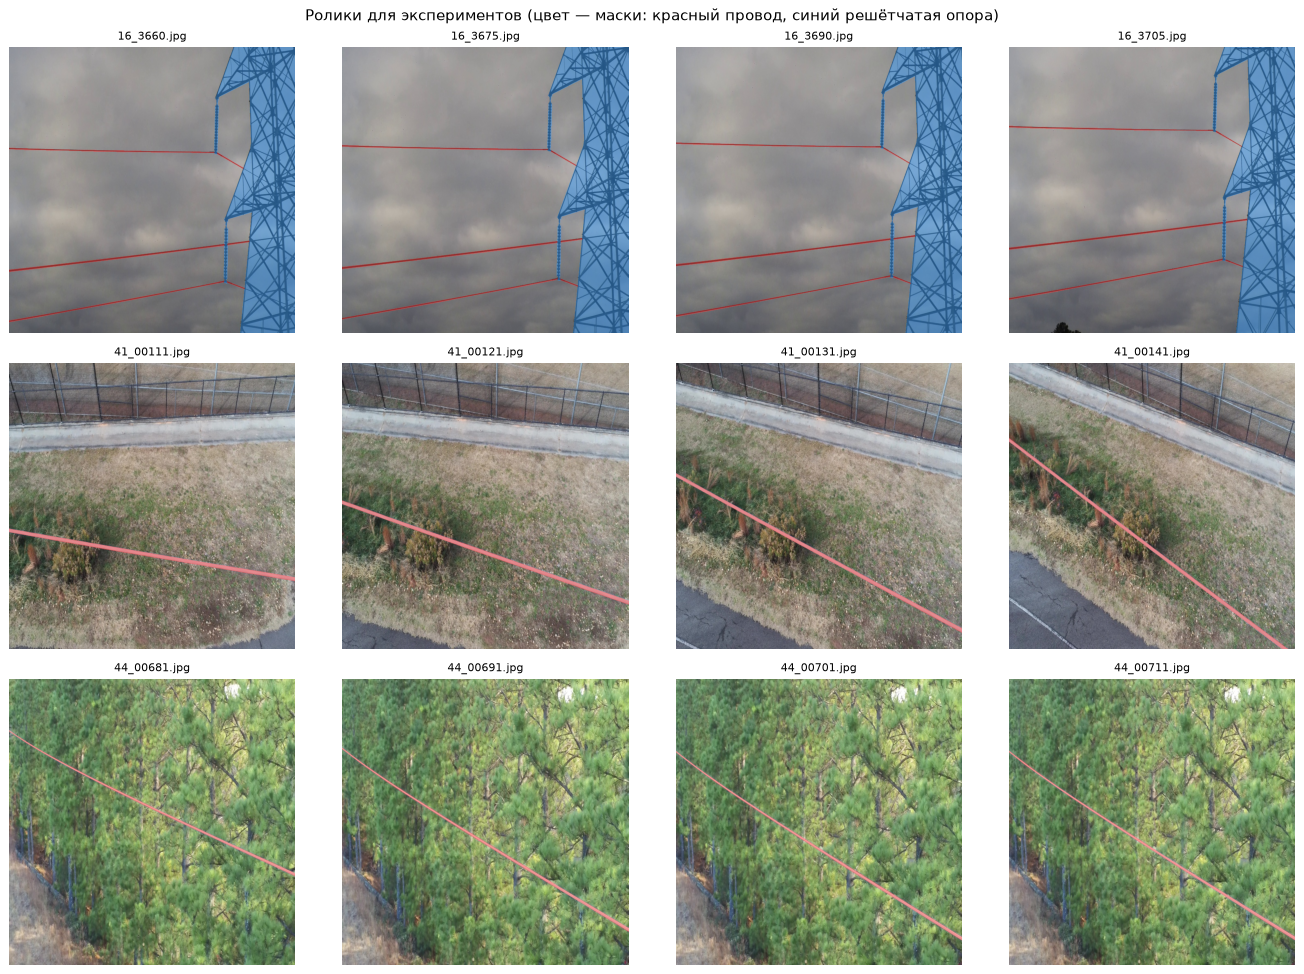

In [3]:
def read_rgb(f): return cv2.cvtColor(cv2.imread(images[f]), cv2.COLOR_BGR2RGB)

def masks(f, H=700, W=700, dilate=0):
    # семантическая карта классов (-1 = фон) и карта экземпляров (0 = фон)
    sem = -np.ones((H, W), np.int16); inst = np.zeros((H, W), np.int32)
    for a in sorted(anns[f], key=lambda a: -a["area"]):   # мелкие поверх крупных
        for poly in a["segmentation"]:
            p = np.array(poly, np.float32).reshape(-1, 2).round().astype(np.int32)
            cv2.fillPoly(sem, [p], int(a["category_id"])); cv2.fillPoly(inst, [p], int(a["id"]))
    return sem, inst

COLORS = np.array([[255, 60, 60], [60, 160, 255], [60, 220, 120], [255, 200, 40]], np.uint8)
def overlay(img, sem, alpha=.5):
    out = img.copy()
    for c in CLASSES:
        m = sem == c; out[m] = (1 - alpha) * out[m] + alpha * COLORS[c]
    return out

CLIPS = {"16": "решётчатая опора, провода, небо", "41": "провод над травой", "44": "провод над лесом"}
fig, ax = plt.subplots(len(CLIPS), 4, figsize=(15, 11))
for r, (k, desc) in enumerate(CLIPS.items()):
    fs = clips[k]
    for c, f in enumerate(fs[10:14]):
        ax[r, c].imshow(overlay(read_rgb(f), masks(f)[0])); ax[r, c].set_title(f, fontsize=9); ax[r, c].axis("off")
    ax[r, 0].set_ylabel(desc)
plt.suptitle("Ролики для экспериментов (цвет — маски: красный провод, синий решётчатая опора)"); plt.tight_layout(); plt.show()

## 2. Модель

In [4]:
model = RoMaV2()
model.apply_setting("precise")   # 800x800 + уточнение 1280x1280, двунаправленно (нужно для цикла A→B→A)
print("lr", (model.H_lr, model.W_lr), "hr", (model.H_hr, model.W_hr), "bidirectional", model.bidirectional)

Using cache found in /Users/feacs/.cache/torch/hub/facebookresearch_dinov3_adc254450203739c8149213a7a69d8d905b4fcfa


2026-11-15 23:31:02 INFO     romav2.romav2 - romav2:117 in __init__ - RoMa v2 initialized.

lr (800, 800) hr (1280, 1280) bidirectional True


## 3. Метрики

- `warp_AB` в каждой точке сетки A говорит, куда она попадает на B (координаты в [-1, 1]).
- **Цикл**: берём `warp_BA` в точке `warp_AB(x)` и сравниваем с x. Ошибка — в пикселях снимка 700×700.
- **Согласованность класса**: класс точки x на A сравниваем с классом в `warp_AB(x)` на B. Маски B слегка расширяем (провода тонкие, 1–3 px), чтобы не штрафовать за субпиксельные сдвиги.
- **Уровень случайности**: доля площади B, занятая этим классом, — столько дала бы случайная точка.
- Учитываем только точки, где модель считает, что соответствие существует (`overlap > 0.5`).

In [5]:
S = 700
def match(fa, fb):
    t = time.time(); p = model.match(read_rgb(fa), read_rgb(fb))
    if device.type == "mps": torch.mps.synchronize()
    p["time"] = time.time() - t
    return p

def cycle_error(p):
    wab = p["warp_AB"].float(); wba = p["warp_BA"].float()
    back = F.grid_sample(wba.permute(0, 3, 1, 2), wab, mode="bilinear", align_corners=False).permute(0, 2, 3, 1)[0]
    h, w = back.shape[:2]
    gx = (torch.arange(w, device=back.device) + .5) / w * 2 - 1; gy = (torch.arange(h, device=back.device) + .5) / h * 2 - 1
    grid = torch.stack(torch.meshgrid(gx, gy, indexing="xy"), -1)
    return ((back - grid).norm(dim=-1) * S / 2).cpu().numpy()

def lookup(arr, warp):
    # значение массива arr (на B) в точках warp (сетка A), ближайший сосед
    h, w = warp.shape[:2]; H, W = arr.shape
    x = ((warp[..., 0] + 1) / 2 * W).astype(int).clip(0, W - 1); y = ((warp[..., 1] + 1) / 2 * H).astype(int).clip(0, H - 1)
    return arr[y, x]

def evaluate(fa, fb, p=None, tol=4):
    p = p or match(fa, fb)
    wab = p["warp_AB"][0].float().cpu().numpy(); ov = p["overlap_AB"][0, ..., 0].float().cpu().numpy()
    h, w = ov.shape
    cyc = cycle_error(p)
    semA, instA = masks(fa); semB, instB = masks(fb)
    semA = cv2.resize(semA.astype(np.int16), (w, h), interpolation=cv2.INTER_NEAREST)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * tol + 1, 2 * tol + 1))
    valid = ov > 0.5
    out = dict(A=fa, B=fb, gap=frame_no(fb) - frame_no(fa), overlap=ov.mean(), time=p["time"],
               cycle_med=np.median(cyc[valid]) if valid.any() else np.nan,
               cycle_gt10=(cyc[valid] > 10).mean() if valid.any() else np.nan)
    for c, name in [(-1, "bg")] + [(c, n) for c, n in CLASSES.items()]:
        mA = (semA == c) & valid
        if mA.sum() < 50: continue
        if c == -1:
            hitB = lookup((semB == -1).astype(np.uint8), wab).astype(bool)
            area = (semB == -1).mean()
        else:
            mB = cv2.dilate((semB == c).astype(np.uint8), k)
            hitB = lookup(mB, wab).astype(bool); area = mB.mean()
        out[f"{name}_cover"] = valid[semA == c].mean()   # доля пикселей класса, где модель уверена
        out[f"{name}_consist"] = hitB[mA].mean(); out[f"{name}_chance"] = area
        out[f"{name}_cycle"] = np.median(cyc[mA])
    return out, p, cyc

## 4. Одна пара: опора (ролик 16)

/Users/feacs/Desktop/study/nir-1/.venv/lib/python3.13/site-packages/romav2/features.py:140: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.autocast(device_type="cuda", enabled=True, dtype=torch.bfloat16):


{'A': '16_3660.jpg', 'B': '16_3675.jpg', 'gap': 15, 'overlap': np.float32(0.14725599), 'time': 2.034, 'cycle_med': np.float32(0.05650378), 'cycle_gt10': np.float64(0.0), 'bg_cover': np.float64(0.006), 'bg_consist': np.float64(0.708), 'bg_chance': np.float64(0.792), 'bg_cycle': np.float32(0.08411264), 'cable_cover': np.float64(0.01), 'cable_consist': np.float64(1.0), 'cable_chance': np.float64(0.045), 'cable_cycle': np.float32(0.06426296), 'tower_lattice_cover': np.float64(0.829), 'tower_lattice_consist': np.float64(1.0), 'tower_lattice_chance': np.float64(0.205), 'tower_lattice_cycle': np.float32(0.055918947)}


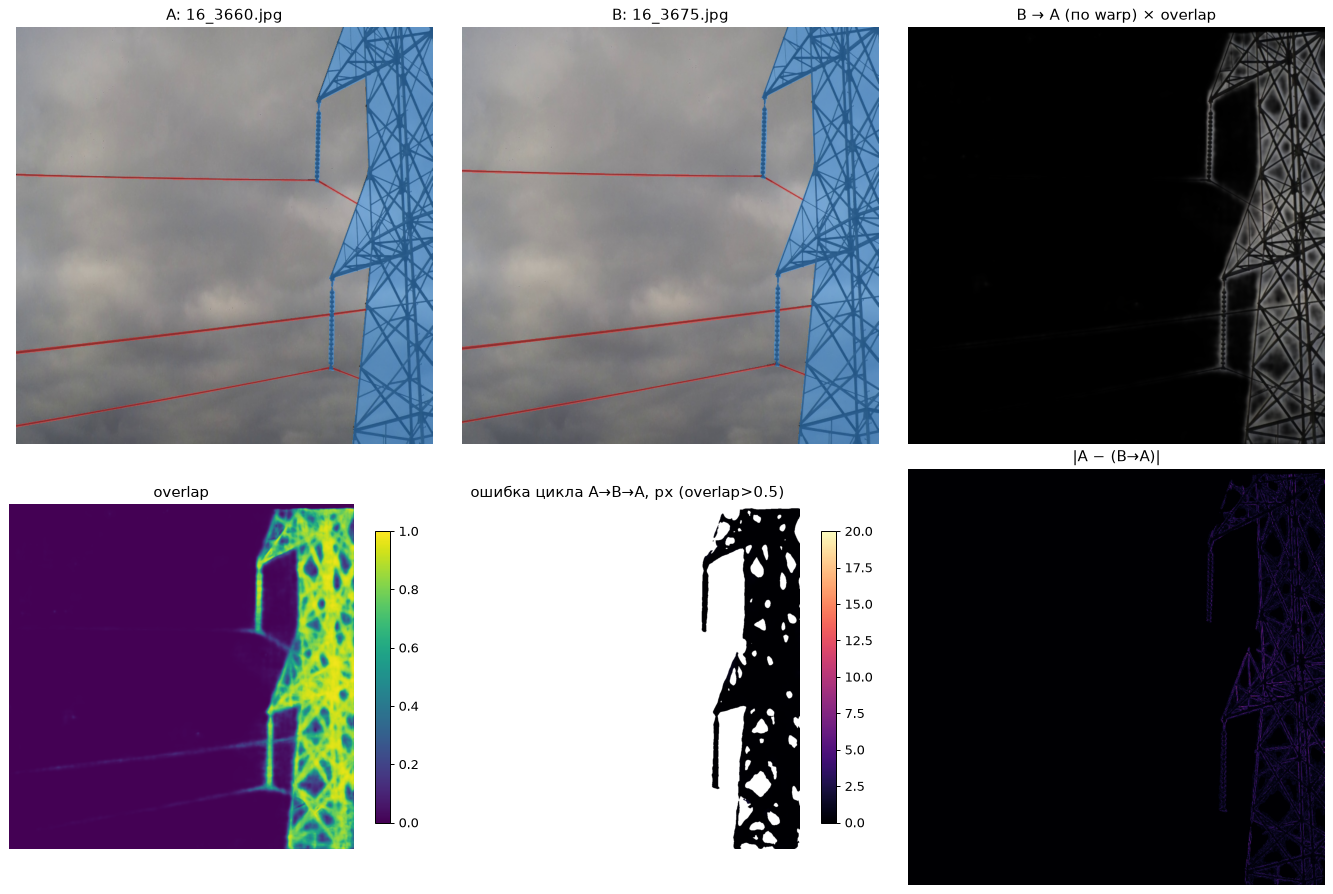

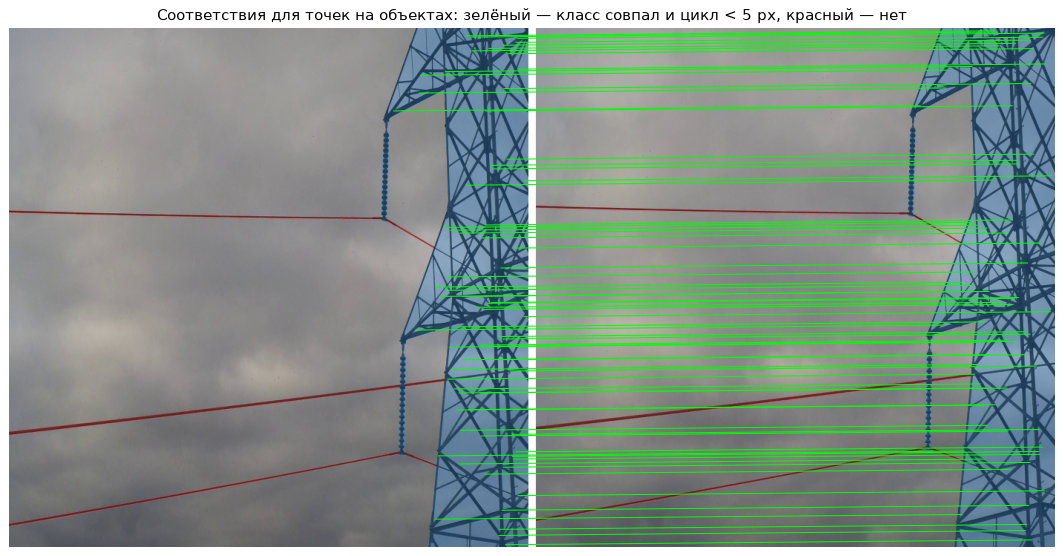

In [6]:
def show_pair(fa, fb, p, cyc, n_lines=70, seed=0):
    A, B = read_rgb(fa), read_rgb(fb)
    semA, _ = masks(fa); semB, _ = masks(fb)
    wab = p["warp_AB"][0].float().cpu().numpy(); ov = p["overlap_AB"][0, ..., 0].float().cpu().numpy()
    h, w = ov.shape
    Bt = torch.from_numpy(cv2.resize(B, (w, h))).permute(2, 0, 1)[None].float().to(device) / 255
    BtoA = F.grid_sample(Bt, p["warp_AB"].float(), mode="bilinear", align_corners=False)[0].permute(1, 2, 0).cpu().numpy()
    fig, ax = plt.subplots(2, 3, figsize=(15, 10))
    ax[0, 0].imshow(overlay(A, semA)); ax[0, 0].set_title(f"A: {fa}")
    ax[0, 1].imshow(overlay(B, semB)); ax[0, 1].set_title(f"B: {fb}")
    ax[0, 2].imshow(BtoA * ov[..., None]); ax[0, 2].set_title("B → A (по warp) × overlap")
    im = ax[1, 0].imshow(ov, vmin=0, vmax=1); ax[1, 0].set_title("overlap"); plt.colorbar(im, ax=ax[1, 0], shrink=.7)
    im = ax[1, 1].imshow(np.where(ov > .5, cyc, np.nan), vmin=0, vmax=20, cmap="magma"); ax[1, 1].set_title("ошибка цикла A→B→A, px (overlap>0.5)"); plt.colorbar(im, ax=ax[1, 1], shrink=.7)
    ax[1, 2].imshow(np.abs(cv2.resize(A, (w, h)) / 255 - BtoA).mean(-1) * (ov > .5), cmap="magma", vmax=.3); ax[1, 2].set_title("|A − (B→A)|")
    for a in ax.ravel(): a.axis("off")
    plt.tight_layout(); plt.show()

    # линии соответствий для точек на объектах: зелёные — класс совпал и цикл < 5 px, красные — нет
    semA_s = cv2.resize(semA, (w, h), interpolation=cv2.INTER_NEAREST)
    semB_d = {c: cv2.dilate((semB == c).astype(np.uint8), np.ones((9, 9), np.uint8)) for c in CLASSES}
    ys, xs = np.where((semA_s >= 0) & (ov > .5))
    rng = np.random.default_rng(seed); idx = rng.choice(len(ys), min(n_lines, len(ys)), replace=False)
    canvas = np.concatenate([overlay(A, semA, .3), np.full((S, 10, 3), 255, np.uint8), overlay(B, semB, .3)], 1)
    plt.figure(figsize=(15, 7.5)); plt.imshow(canvas)
    for i in idx:
        y, x = ys[i], xs[i]; c = semA_s[y, x]
        xa, ya = (x + .5) / w * S, (y + .5) / h * S
        xb, yb = (wab[y, x, 0] + 1) / 2 * S, (wab[y, x, 1] + 1) / 2 * S
        ok = semB_d[c][int(np.clip(yb, 0, S - 1)), int(np.clip(xb, 0, S - 1))] and cyc[y, x] < 5
        plt.plot([xa, xb + S + 10], [ya, yb], "-", c="lime" if ok else "red", lw=.8)
    plt.axis("off"); plt.title("Соответствия для точек на объектах: зелёный — класс совпал и цикл < 5 px, красный — нет"); plt.show()

fa, fb = clips["16"][10], clips["16"][11]
res, p, cyc = evaluate(fa, fb)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in res.items()})
show_pair(fa, fb, p, cyc)

## 5. Непрерывные отрезки и соседние кадры

Снимки внутри ролика идут не подряд: бывают разрывы в сотни кадров. Делим ролики на непрерывные отрезки (шаг не больше 15 кадров видео) и берём пары только внутри них.

Для каждого класса:
- `*_cover` — доля пикселей класса, где модель уверена (`overlap > 0.5`); остальные модель «пропускает»;
- `*_consist` — среди уверенных точек доля попаданий в тот же класс на B; `*_chance` — уровень случайности;
- `*_cycle` — медианная ошибка цикла, px.

In [7]:
def runs(clip, max_gap=15, min_len=5):
    fs = clips[clip]; out, cur = [], [fs[0]]
    for a, b in zip(fs, fs[1:]):
        if frame_no(b) - frame_no(a) <= max_gap: cur.append(b)
        else:
            if len(cur) >= min_len: out.append(cur)
            cur = [b]
    if len(cur) >= min_len: out.append(cur)
    return out

RUNS = {k: runs(k) for k in CLIPS}
for k, rs in RUNS.items():
    print(k, [(r[0], r[-1], len(r)) for r in rs])

16 [('16_3645.jpg', '16_3735.jpg', 7), ('16_3855.jpg', '16_4005.jpg', 11)]
41 [('41_00021.jpg', '41_00761.jpg', 75)]
44 [('44_00081.jpg', '44_00151.jpg', 8), ('44_00681.jpg', '44_00721.jpg', 5), ('44_01041.jpg', '44_01491.jpg', 46)]


In [8]:
MAX_PAIRS = 30
res_rows = []
for k, rs in RUNS.items():
    pairs = [(a, b) for r in rs for a, b in zip(r, r[1:])][:MAX_PAIRS]
    for fa, fb in pairs:
        r, _, _ = evaluate(fa, fb); r["clip"] = k; res_rows.append(r)
seqdf = pd.DataFrame(res_rows)
print(f"пар: {len(seqdf)}, среднее время на пару: {seqdf.time.mean():.2f} c")
order = ["overlap", "cycle_med", "cycle_gt10"]
for n in ["bg", "cable", "tower_lattice", "tower_tucohy", "tower_wooden"]:
    order += [c for c in [f"{n}_cover", f"{n}_consist", f"{n}_chance", f"{n}_cycle"] if c in seqdf]
seqdf.groupby("clip")[order].mean().T.round(3)

пар: 76, среднее время на пару: 1.92 c


clip,16,41,44
overlap,0.195,0.827,0.767
cycle_med,0.064,0.042,0.052
cycle_gt10,0.000,0.002,0.001
bg_cover,0.169,0.853,0.841
bg_consist,0.944,0.998,0.998
bg_chance,0.912,0.978,0.976
bg_cycle,0.074,0.041,0.051
cable_cover,0.037,0.764,0.795
cable_consist,1.000,0.856,0.950
cable_chance,0.043,0.045,0.061


## 6. Псевдо-истина: цепочка через соседние кадры

Метрики выше видят только грубые ошибки (опора → небо). Ошибка «перескочил на соседнюю траверсу или ячейку решётки» для них невидима: опора попала на опору, и цикл тоже может сойтись.

Для коротких шагов RoMa почти безошибочна (цикл < 0.1 px). Поэтому строим опорное поле для пары (A, B) с большим шагом **цепочкой**: A→A+1→…→B через все промежуточные кадры. Расхождение прямого поля A→B с цепочкой показывает, где прямой матч ошибся.

- `chain_err` — расстояние между прямым и цепочным соответствием, px (на снимке 700×700);
- **«тихая» ошибка** — модель уверена (`overlap > 0.5`), а расхождение с цепочкой > 10 px.

In [9]:
CH = 640  # разрешение, на котором храним поля для цепочки
def small(p, key):
    w = p[f"warp_{key}"].float().permute(0, 3, 1, 2); o = p[f"overlap_{key}"].float().permute(0, 3, 1, 2)
    w = F.interpolate(w, size=(CH, CH), mode="bilinear", align_corners=False)
    o = F.interpolate(o, size=(CH, CH), mode="bilinear", align_corners=False)
    return w, o   # (1,2,CH,CH), (1,1,CH,CH)

def compose(w1, o1, w2, o2):
    # x -> w1(x) -> w2(w1(x));  уверенность — минимум вдоль цепочки
    g = w1.permute(0, 2, 3, 1)
    return (F.grid_sample(w2, g, mode="bilinear", align_corners=False),
            torch.minimum(o1, F.grid_sample(o2, g, mode="bilinear", align_corners=False)))

def run_chain_eval(run, steps, max_starts=12):
    cons = {}  # i -> поле i->i+1
    for i in range(len(run) - 1):
        cons[i] = small(match(run[i], run[i + 1]), "AB")
    rows, examples = [], {}
    for step in steps:
        for i in range(0, min(len(run) - step, max_starts)):
            w, o = cons[i]
            for j in range(i + 1, i + step):
                w, o = compose(w, o, *cons[j])
            fa, fb = run[i], run[i + step]
            pd_ = match(fa, fb); wd, od = small(pd_, "AB")
            err = ((wd - w).norm(dim=1)[0] * S / 2).cpu().numpy()
            od = od[0, 0].cpu().numpy(); oc = o[0, 0].cpu().numpy()
            semA = cv2.resize(masks(fa)[0].astype(np.int16), (CH, CH), interpolation=cv2.INTER_NEAREST)
            ref = oc > 0.5           # где цепочка надёжна
            row = dict(A=fa, B=fb, step=step, gap=frame_no(fb) - frame_no(fa), chain_cover=ref.mean())
            for c, n in [(-1, "bg"), (0, "cable"), (1, "tower_lattice"), (2, "tower_tucohy"), (3, "tower_wooden")]:
                m = ref & (semA == c)
                if m.sum() < 50: continue
                conf = m & (od > 0.5)
                row[f"{n}_direct_cover"] = conf.sum() / m.sum(); row[f"{n}_n"] = int(conf.sum())
                row[f"{n}_err_med"] = np.median(err[conf]) if conf.any() else np.nan
                row[f"{n}_silent"] = (err[conf] > 10).mean() if conf.any() else np.nan
            rows.append(row); examples[(fa, fb)] = (err, od, oc)
    return pd.DataFrame(rows), examples

CHAIN_RUNS = {"16": RUNS["16"][0], "41": max(RUNS["41"], key=len)[:30]}   # 16: отрезок 3645–3735, где есть опора
chain_res, chain_ex = {}, {}
for k, run in CHAIN_RUNS.items():
    steps = [1, 2, 3, 4, 6] if len(run) < 20 else [1, 3, 5, 10, 20]
    df, ex = run_chain_eval(run, steps); df["clip"] = k
    chain_res[k] = df; chain_ex.update(ex)
    print(k, run[0], "…", run[-1], len(run), "кадров")
chaindf = pd.concat(chain_res.values())
cols = ["gap", "chain_cover"] + [c for c in chaindf.columns if c.endswith(("_direct_cover", "_err_med", "_silent"))]
chaindf.groupby(["clip", "step"])[cols].mean().round(3)

/Users/feacs/Desktop/study/nir-1/.venv/lib/python3.13/site-packages/romav2/features.py:140: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.autocast(device_type="cuda", enabled=True, dtype=torch.bfloat16):


16 16_3645.jpg … 16_3735.jpg 7 кадров


41 41_00021.jpg … 41_00311.jpg 30 кадров


gap  chain_cover  bg_direct_cover  bg_err_med  bg_silent  \
clip step                                                               
16   1      15.0        0.165            1.000       0.000      0.000   
     2      30.0        0.154            0.884       0.191      0.000   
     3      45.0        0.146            0.899       0.234      0.000   
     4      60.0        0.140            0.899       0.329      0.000   
     6      90.0        0.133            0.883       0.453      0.000   
41   1      10.0        0.858            1.000       0.000      0.000   
     3      30.0        0.646            0.990       0.127      0.001   
     5      50.0        0.500            0.984       0.173      0.001   
     10    100.0        0.204            0.971       0.287      0.002   
     20    200.0        0.017            0.993       0.480      0.008   

           cable_direct_cover  cable_err_med  cable_silent  \
clip step                                                    
16   1                  1.000          0.000         0.000   
     2                  0.806          0.140         0.000   
     3                  0.862          0.247         0.000   
     4                  0.940          0.297         0.000   
     6                    NaN            NaN           NaN   
41   1                  1.000          0.000         0.000   
     3                  0.522         12.433         0.509   
     5                  0.262         33.309         0.454   
     10                 0.276         43.637         0.489   
     20                 0.360         36.126         0.528   

           tower_lattice_direct_cover  tower_lattice_err_med  \
clip step                                                      
16   1                          1.000                  0.000   
     2                          0.973                  0.155   
     3                          0.977                  0.190   
     4                          0.966                  0.230   
     6                          0.962                  0.358   
41   1                            NaN                    NaN   
     3                            NaN                    NaN   
     5                            NaN                    NaN   
     10                           NaN                    NaN   
     20                           NaN                    NaN   

           tower_lattice_silent  
clip step                        
16   1                      0.0  
     2                      0.0  
     3                      0.0  
     4                      0.0  
     6                      0.0  
41   1                      NaN  
     3                      NaN  
     5                      NaN  
     10                     NaN  
     20                     NaN

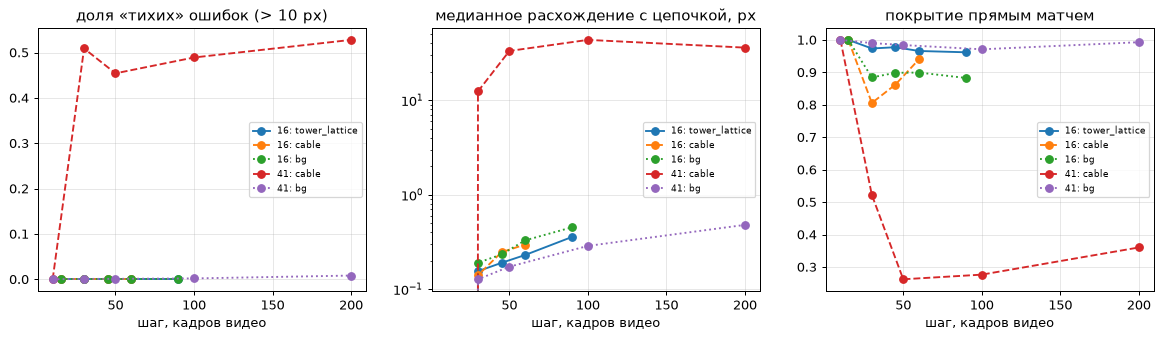

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for (k, g) in chaindf.groupby("clip"):
    t = g.groupby("step").mean(numeric_only=True)
    for n, ls in [("tower_lattice", "-"), ("cable", "--"), ("bg", ":")]:
        if f"{n}_silent" in t and t[f"{n}_silent"].notna().any():
            ax[0].plot(t.gap, t[f"{n}_silent"], "o" + ls, label=f"{k}: {n}")
            ax[1].plot(t.gap, t[f"{n}_err_med"], "o" + ls, label=f"{k}: {n}")
            ax[2].plot(t.gap, t[f"{n}_direct_cover"], "o" + ls, label=f"{k}: {n}")
ax[0].set_title("доля «тихих» ошибок (> 10 px)"); ax[1].set_title("медианное расхождение с цепочкой, px"); ax[2].set_title("покрытие прямым матчем")
for a in ax: a.set_xlabel("шаг, кадров видео"); a.grid(alpha=.3); a.legend(fontsize=7)
ax[1].set_yscale("log"); plt.show()

{'A': '41_00111.jpg', 'B': '41_00141.jpg', 'gap': 30, 'cable_silent': 0.9593392630241423, 'tower_lattice_silent': nan}


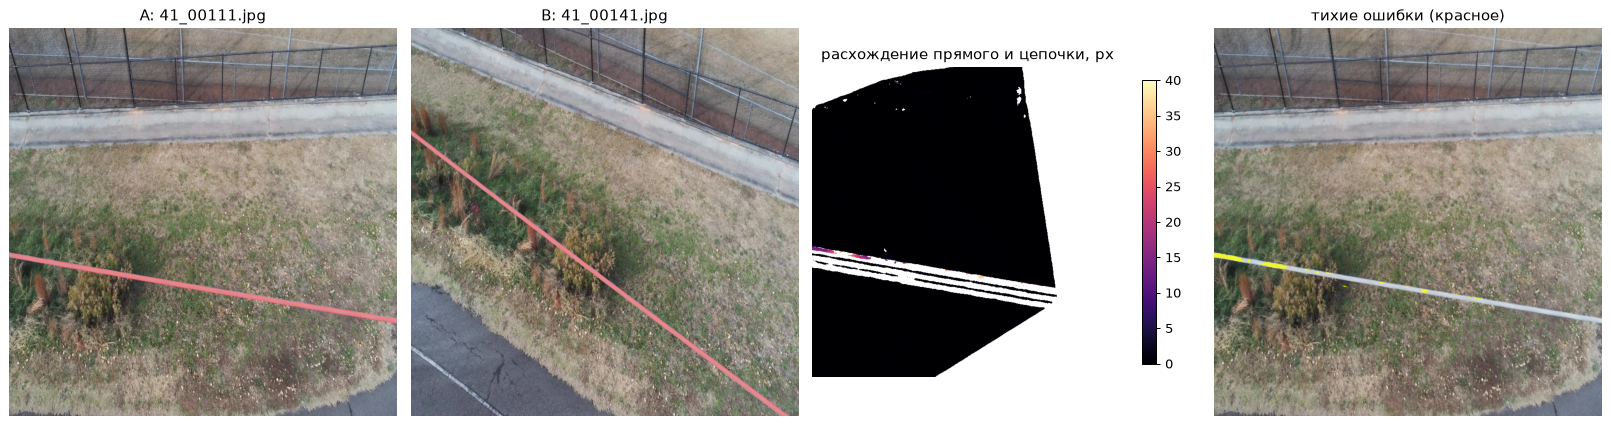

/Users/feacs/Desktop/study/nir-1/.venv/lib/python3.13/site-packages/romav2/features.py:140: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.autocast(device_type="cuda", enabled=True, dtype=torch.bfloat16):


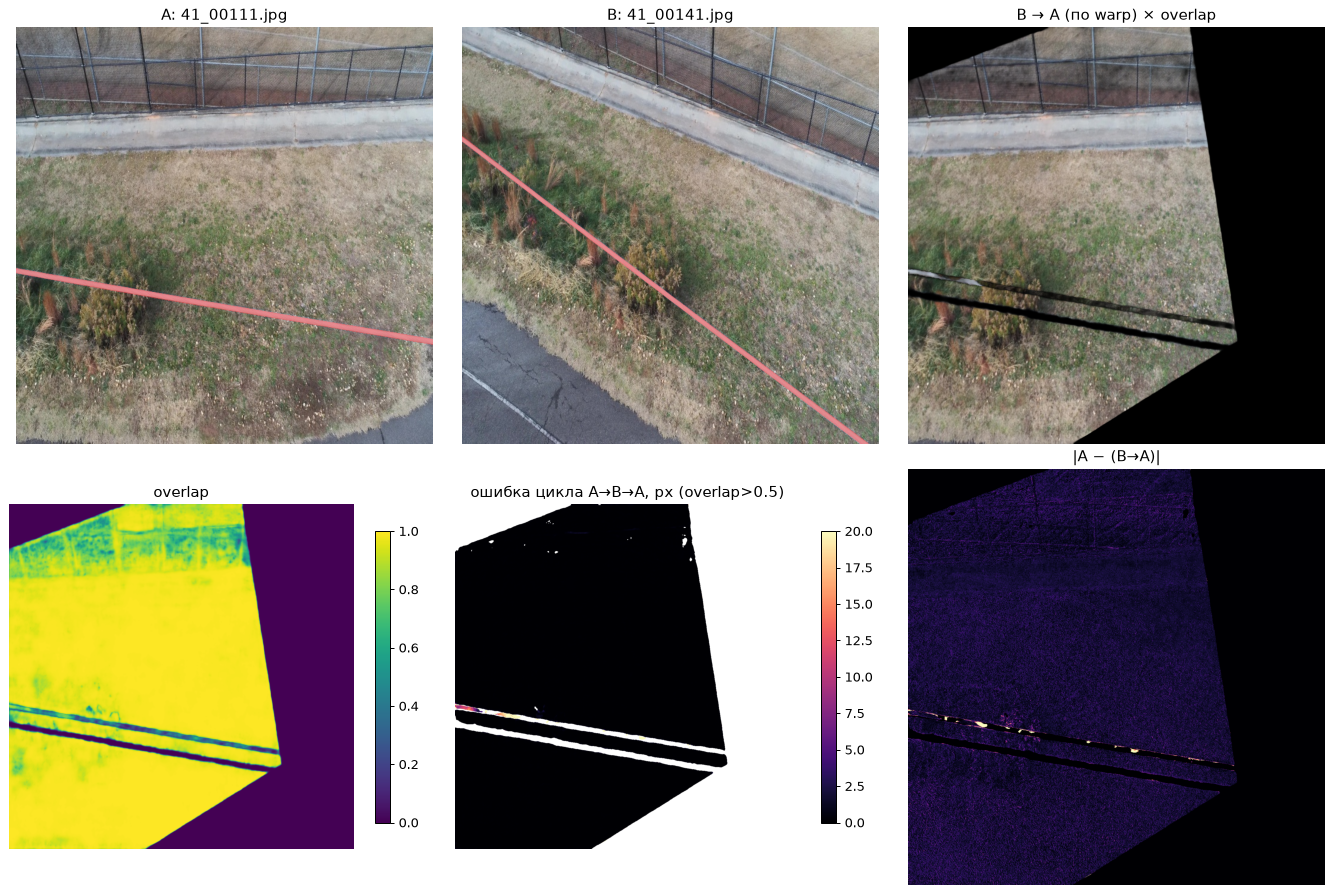

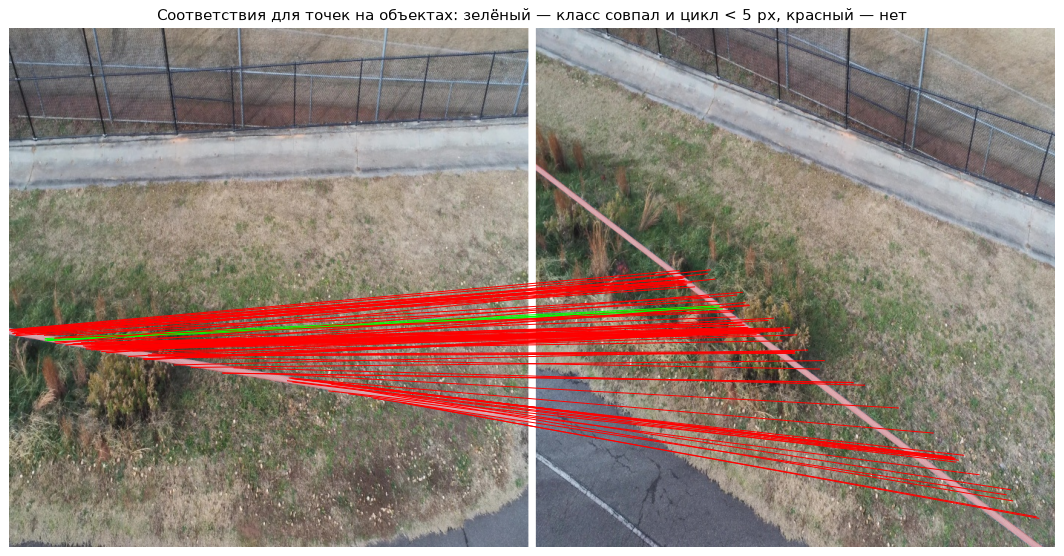

In [11]:
# пример: пара с наибольшей долей тихих ошибок на объектах среди пар, где на объектах >= 300 уверенных точек
obj = [n for n in ["cable", "tower_lattice", "tower_tucohy", "tower_wooden"] if f"{n}_silent" in chaindf]
obj_cols = [f"{n}_silent" for n in obj]
chaindf["obj_n"] = chaindf[[f"{n}_n" for n in obj]].sum(axis=1)
chaindf["obj_silent"] = sum(chaindf[f"{n}_silent"].fillna(0) * chaindf[f"{n}_n"].fillna(0) for n in obj) / chaindf.obj_n.clip(lower=1)
w = chaindf[chaindf.obj_n >= 300].sort_values("obj_silent", ascending=False).iloc[0]
print(w[["A", "B", "gap"] + obj_cols].to_dict())
err, od, oc = chain_ex[(w.A, w.B)]
A, B = read_rgb(w.A), read_rgb(w.B)
fig, ax = plt.subplots(1, 4, figsize=(18, 4.8))
ax[0].imshow(overlay(A, masks(w.A)[0])); ax[0].set_title(f"A: {w.A}")
ax[1].imshow(overlay(B, masks(w.B)[0])); ax[1].set_title(f"B: {w.B}")
im = ax[2].imshow(np.where((od > .5) & (oc > .5), err, np.nan), cmap="magma", vmin=0, vmax=40); ax[2].set_title("расхождение прямого и цепочки, px"); plt.colorbar(im, ax=ax[2], shrink=.7)
ax[3].imshow(cv2.resize(A, (CH, CH))); ax[3].imshow(np.where((od > .5) & (oc > .5) & (err > 10), 1, np.nan), cmap="autumn", alpha=.8, vmin=0, vmax=1); ax[3].set_title("тихие ошибки (красное)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
p = match(w.A, w.B); show_pair(w.A, w.B, p, cycle_error(p), n_lines=90)

## 7. Выводы

Прогон: RoMa v2 `precise` (800 + уточнение 1280, двунаправленно), Apple M5 Pro / MPS, 76 пар соседних кадров из роликов 16, 41, 44 + цепочки для 16 и 41. Время — **≈1.9 с на пару**.

**1. Решётчатая опора (ролик 16) — сопоставляется практически идеально.**
- Покрытие уверенным матчем 82 %, согласованность класса **100 %** (случайный уровень — 21 %), медианная ошибка цикла 0.05 px.
- Проверка цепочкой: при шаге до 90 кадров видео расхождение прямого поля с цепочкой — медиана 0.2–0.36 px, «тихих» ошибок > 10 px — **0 %**, покрытие 96–98 %.
- Ожидаемого «съезда на соседнюю ячейку решётки» не наблюдается: глобальный контекст (DINOv3) + уточнение держат повторяющуюся структуру.

**2. Небо и провода на фоне неба модель честно не матчит.**
- В ролике 16 overlap всего 0.20: небо (`bg_cover` 0.17) и провода на фоне неба (`cable_cover` 0.04) почти целиком помечены как «соответствия нет». Там, где модель всё же уверена, ошибки нет (согласованность провода 100 %, цикл 0.1 px).
- Т. е. на однородном фоне RoMa v2 отказывается, а не ошибается — для подсчёта по маске `overlap` это корректное поведение, но провода в небе такой матчер не отслеживает.

**3. Главная проблема — провода над текстурным фоном (ролик 41, трава/земля).**
- Грубые метрики выглядят прилично: согласованность класса 86 % (случайно 4.5 %), но медианный цикл на проводе уже **3.9 px** против 0.04 px на фоне.
- Цепочка вскрывает ошибку: начиная с шага 30 кадров **≈50 % уверенных точек провода — «тихие» ошибки** (> 10 px), медианное расхождение 12–44 px; покрытие провода падает до 26–52 %. Фон в том же ролике — 0.1–0.5 px и < 1 % ошибок.
- По визуализации (худшая пара 41_00111 → 41_00141, 96 % тихих ошибок на проводе) точки провода попадают **на провод на B, но смещены вдоль него** и в перемешанном порядке. Это ошибка, которую метрика согласованности класса не видит в принципе.
- Вероятные причины: (а) провод тонкий и однородный по длине — вдоль него нет признаков, чтобы зафиксировать положение (проблема апертуры); (б) провод ближе к камере, чем земля, и движется с другим параллаксом, а модель тянет его поле к движению доминирующего фона.
- В ролике 44 (провод над лесом) ситуация мягче: согласованность 95 %, цикл ≈ 1 px — на соседних кадрах проблема проявляется слабее; цепочкой этот ролик не проверялся.

**4. Методические выводы.**
- Согласованность класса и цикл A→B→A ловят только грубые ошибки; для тонких и повторяющихся объектов нужна псевдо-истина (цепочка соседних кадров) — она и показала разницу между опорой и проводом.
- Ошибка цикла хорошо коррелирует с проблемой: медианный цикл на проводе 3.9 px vs < 0.1 px на остальном — дешёвый индикатор ненадёжных областей без цепочки.
- Ограничения: цепочка сама может накапливать дрейф (это верхняя оценка ошибки прямого матча, а не истина); на больших шагах в ролике 41 надёжная часть цепочки покрывает лишь 2–20 % кадра, статистика для шага 200 малонадёжна; опора проверена только на одном отрезке ролика 16 (7 кадров).

**Что дальше:** проверить провода цепочкой на ролике 44 и других; сравнить с матчингом только по маске провода / с ограничением по эпиполярной геометрии; посмотреть, снижает ли ошибку вдоль провода режим без уточнения (`base`) или большее разрешение.